# Lab 15.3: A Truth Probe with Controls (the Chapter 15 case study)

Run every cell in order. Nothing needs to be edited. We build 288 short statements about where 72 cities are, read GPT-2 small's residual stream at the final period, and ask whether a linear probe can tell true statements from false ones, and what exactly it has learned. Checkpoints are in the README.

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, torch
from transformer_lens import HookedTransformer
torch.manual_seed(0)
t0 = time.time()
model = HookedTransformer.from_pretrained("gpt2", device="cpu")  # GPT-2 small, 124M parameters
model.eval()
print("layers:", model.cfg.n_layers, "| width:", model.cfg.d_model, "| vocabulary:", model.cfg.d_vocab)

Loaded pretrained model gpt2 into HookedTransformer
layers: 12 | width: 768 | vocabulary: 50257


In [2]:
CITIES = [("Tokyo","Japan"),("Osaka","Japan"),("Paris","France"),("Lyon","France"),("Berlin","Germany"),("Munich","Germany"),
("Madrid","Spain"),("Barcelona","Spain"),("Rome","Italy"),("Milan","Italy"),("London","the United Kingdom"),("Manchester","the United Kingdom"),
("Moscow","Russia"),("Beijing","China"),("Shanghai","China"),("Mumbai","India"),("Delhi","India"),("Cairo","Egypt"),
("Toronto","Canada"),("Vancouver","Canada"),("Chicago","the United States"),("Boston","the United States"),("Sydney","Australia"),("Melbourne","Australia"),
("Mexico City","Mexico"),("Buenos Aires","Argentina"),("Lima","Peru"),("Bogota","Colombia"),("Santiago","Chile"),("Rio de Janeiro","Brazil"),
("Sao Paulo","Brazil"),("Lagos","Nigeria"),("Nairobi","Kenya"),("Johannesburg","South Africa"),("Cape Town","South Africa"),("Istanbul","Turkey"),
("Athens","Greece"),("Lisbon","Portugal"),("Amsterdam","the Netherlands"),("Brussels","Belgium"),("Vienna","Austria"),("Zurich","Switzerland"),
("Stockholm","Sweden"),("Oslo","Norway"),("Copenhagen","Denmark"),("Helsinki","Finland"),("Warsaw","Poland"),("Prague","the Czech Republic"),
("Budapest","Hungary"),("Dublin","Ireland"),("Seoul","South Korea"),("Bangkok","Thailand"),("Hanoi","Vietnam"),("Jakarta","Indonesia"),
("Manila","the Philippines"),("Karachi","Pakistan"),("Tehran","Iran"),("Baghdad","Iraq"),("Riyadh","Saudi Arabia"),("Dubai","the United Arab Emirates"),
("Havana","Cuba"),("Kyoto","Japan"),("Hamburg","Germany"),("Seville","Spain"),("Naples","Italy"),("Marseille","France"),
("Montreal","Canada"),("Seattle","the United States"),("Perth","Australia"),("Auckland","New Zealand"),("Krakow","Poland"),("Casablanca","Morocco")]
rng = np.random.default_rng(0)
countries = sorted(set(c for _, c in CITIES))
rows = []
for i, (city, ctry) in enumerate(CITIES):
    wrong = str(rng.choice([c for c in countries if c != ctry]))
    rows += [(i, city, ctry, 1, "plain"), (i, city, wrong, 0, "plain"), (i, city, ctry, 0, "negated"), (i, city, wrong, 1, "negated")]
data = pd.DataFrame(rows, columns=["city_id", "city", "country", "true", "form"])
data["text"] = [f"The city of {r.city} is {'not ' if r.form == 'negated' else ''}in {r.country}." for r in data.itertuples()]
data.groupby(["form", "true"]).head(1)[["text", "form", "true"]]

,text,form,true
0,The city of Tokyo is in Japan.,plain,1
1,The city of Tokyo is in Turkey.,plain,0
2,The city of Tokyo is not in Japan.,negated,0
3,The city of Tokyo is not in Turkey.,negated,1


In [3]:
def resid_at_end(m, text):
    """Residual stream at the last token: embeddings (layer 0) and after each of the 12 blocks."""
    with torch.no_grad():
        _, c = m.run_with_cache(m.to_tokens(text), names_filter=lambda n: n.endswith("resid_post") or n == "blocks.0.hook_resid_pre")
    return torch.stack([c["blocks.0.hook_resid_pre"][0, -1]] + [c[f"blocks.{l}.hook_resid_post"][0, -1] for l in range(12)]).numpy()

def logprob_country(prefix, country):
    pre = model.to_tokens(prefix); ct = model.to_tokens(" " + country, prepend_bos=False)
    with torch.no_grad():
        lg = model(torch.cat([pre, ct], 1)).log_softmax(-1)
    n = pre.shape[1]
    return sum(float(lg[0, n - 1 + j, ct[0, j]]) for j in range(ct.shape[1]))

A = np.array([resid_at_end(model, t) for t in data.text])
data["logprob"] = [logprob_country(f"The city of {r.city} is {'not ' if r.form == 'negated' else ''}in", r.country) for r in data.itertuples()]
plain, neg = (data.form == "plain").values, (data.form == "negated").values
Y, G = data.true.values, data.city_id.values
lp = data.logprob.values.reshape(-1, 4)
print("activations:", A.shape)
print("GPT-2 prefers the right country over the wrong one for", f"{(lp[:,0] > lp[:,1]).mean():.0%}", "of cities")
print("mean log probability after 'is in':     right", lp[:,0].mean().round(2), " wrong", lp[:,1].mean().round(2))
print("mean log probability after 'is not in': right", lp[:,2].mean().round(2), " wrong", lp[:,3].mean().round(2))

activations: (288, 13, 768)
GPT-2 prefers the right country over the wrong one for 99% of cities
mean log probability after 'is in':     right -6.7  wrong -10.6
mean log probability after 'is not in': right -5.22  wrong -10.26


**Checkpoint 1.** GPT-2 small prefers the right country for 71 of 72 cities (99 percent). After "is not in" it *still* gives the right country a much higher log probability than the wrong one: its next-token predictions largely ignore "not".

## Probes layer by layer, with baselines

We split by city (GroupKFold, five folds), so a city never appears in both training and test data. We compare a logistic regression probe with a mass-mean (difference-of-means) probe, and with the same logistic probe on a randomly initialized GPT-2 that has the same architecture.

In [4]:
import copy
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
LR = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))
gkf = GroupKFold(5)
def cv(X, y, g, kind="lr"):
    acc = []
    for trn, tst in gkf.split(X, y, g):
        if kind == "lr":
            acc.append(LR().fit(X[trn], y[trn]).score(X[tst], y[tst]))
        else:
            mu1, mu0 = X[trn][y[trn] == 1].mean(0), X[trn][y[trn] == 0].mean(0); w = mu1 - mu0
            acc.append(((X[tst] @ w > (mu1 + mu0) @ w / 2) == y[tst]).mean())
    return float(np.mean(acc))

cfg = copy.deepcopy(model.cfg); cfg.init_weights = True
torch.manual_seed(0); rnd = HookedTransformer(cfg); rnd.init_weights(); rnd.eval()
AR = np.array([resid_at_end(rnd, t) for t in data.text[plain]])
A2 = np.array([resid_at_end(model, f"{r.city} is a city located in {r.country}.") for r in data[plain].itertuples()])

res = []
for l in range(13):
    X = A[:, l]
    probe = LR().fit(X[plain], Y[plain])
    res.append({"layer": l,
                "logistic (plain, held-out cities)": cv(X[plain], Y[plain], G[plain]),
                "mass-mean (plain, held-out cities)": cv(X[plain], Y[plain], G[plain], "mm"),
                "logistic on random GPT-2": cv(AR[:, l], Y[plain], G[plain]),
                "plain probe tested on negated": probe.score(X[neg], Y[neg]),
                "plain probe tested on paraphrase (accuracy)": probe.score(A2[:, l], Y[plain]),
                "plain probe tested on paraphrase (AUROC)": roc_auc_score(Y[plain], probe.decision_function(A2[:, l])) if l else 0.5,
                "logistic trained on plain + negated": cv(X, Y, G)})
truth = pd.DataFrame(res).set_index("layer").round(3)
truth.to_csv("truth_results.csv")
truth

,"logistic (plain, held-out cities)","mass-mean (plain, held-out cities)",logistic on random GPT-2,plain probe tested on negated,plain probe tested on paraphrase (accuracy),plain probe tested on paraphrase (AUROC),logistic trained on plain + negated
layer,,,,,,,
0,0.492,0.499,0.492,0.521,0.542,0.500,0.495
1,0.597,0.535,0.479,0.139,0.639,0.740,0.499
2,0.758,0.590,0.507,0.194,0.521,0.763,0.569
3,0.829,0.695,0.472,0.007,0.632,0.842,0.646
4,0.820,0.758,0.492,0.083,0.708,0.808,0.744
5,0.904,0.828,0.527,0.021,0.646,0.933,0.887
6,0.904,0.834,0.535,0.021,0.514,0.917,0.893
7,0.910,0.917,0.529,0.479,0.500,0.889,0.925
8,0.910,0.932,0.541,0.340,0.500,0.823,0.904


**Checkpoint 2.** On held-out cities the logistic probe reaches about 0.90 from layer 5 on (0.92 at layer 10); the mass-mean probe peaks at about 0.93 (layers 8 and 9). Layer 0 and the random network stay near 0.5. Tested on negated statements, the plain probe falls far *below* chance (for example about 0.34 at layer 8): it calls "Tokyo is not in Japan" true. On the paraphrase, accuracy drops to 0.50 in later layers even though AUROC stays around 0.8: the direction partly transfers, the threshold does not. Trained on plain and negated statements together, a probe again reaches about 0.9.

correlation of probe score with the model's log probability of the country:
  plain statements   0.73
  negated statements 0.82


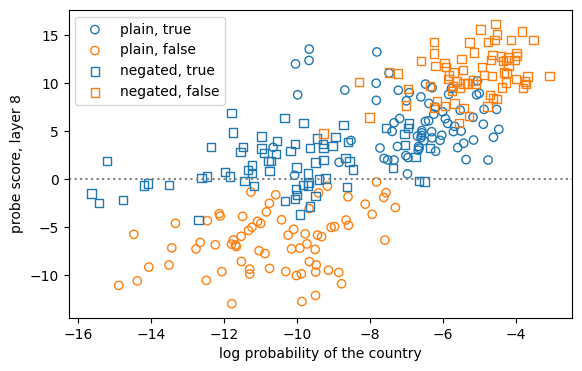

In [5]:
import matplotlib.pyplot as plt
L = 8
probe = LR().fit(A[plain, L], Y[plain])
s = probe.decision_function(A[:, L])
print("correlation of probe score with the model's log probability of the country:")
print("  plain statements  ", np.corrcoef(s[plain], data.logprob[plain])[0, 1].round(2))
print("  negated statements", np.corrcoef(s[neg], data.logprob[neg])[0, 1].round(2))
fig, ax = plt.subplots(figsize=(6.5, 4))
for form, mk in (("plain", "o"), ("negated", "s")):
    for t, col in ((1, "tab:blue"), (0, "tab:orange")):
        sel = ((data.form == form) & (data.true == t)).values
        ax.scatter(data.logprob[sel], s[sel], marker=mk, facecolors="none", edgecolors=col, label=f"{form}, {'true' if t else 'false'}")
ax.axhline(0, ls=":", color="gray"); ax.set_xlabel("log probability of the country"); ax.set_ylabel(f"probe score, layer {L}"); ax.legend(); plt.show()

**Checkpoint 3.** The correlations are about 0.73 (plain) and 0.82 (negated). The probe score rises with how well the country fits the city, whether or not the sentence says "not".

## A control task: how much can a probe memorize?

Hewitt and Liang (2019) suggest comparing a probe's accuracy with its accuracy on a *control task* whose labels mean nothing. Here each country gets a random bit, and the probe must predict the bit of the country named in the sentence.

In [6]:
bit = {c: int(b) for c, b in zip(countries, np.random.default_rng(1).integers(0, 2, len(countries)))}
Yc = data.country.map(bit).values
ctrl = [cv(A[plain, l], Yc[plain], G[plain]) for l in range(13)]
pd.DataFrame({"truth probe": truth.iloc[:, 0], "control task (random bit per country)": np.round(ctrl, 3)})

,truth probe,control task (random bit per country)
layer,,
0,0.492,0.605
1,0.597,0.870
2,0.758,0.821
3,0.829,0.890
4,0.820,0.904
5,0.904,0.910
6,0.904,0.930
7,0.910,0.938
8,0.910,0.924


**Checkpoint 4.** The control task reaches about 0.9 in middle layers: the representation at the period records which country was named, and a linear probe can read that identity and memorize arbitrary labels for it. This does not make the truth result meaningless (truth is not a function of the country alone, and cities are held out), but it shows how much a probe can extract from information that has nothing to do with the property you care about. Total run time:

In [7]:
print(f"{(time.time() - t0) / 60:.1f} minutes")

1.8 minutes
